# AcneLens — Deteksi Papula, Pustula, dan Kulit Normal dengan SURF + HOG + SVM

Implementasi ulang jurnal **"Analisis Kinerja Ekstraksi Fitur SURF dan HOG pada Deteksi Acne Vulgaris"**
(Luthfi & Ali, *Jurnal Andalas: Rekayasa dan Penerapan Teknologi*, Vol. 06 No. 01, 2026) — file `docs/145 Prod-1.pdf`.

**Alur notebook (sesuai Gambar 1 pada jurnal):**

| No | Tahap | Keterangan |
|---|---|---|
| 1 | Download dataset | Kaggle *Acne_dataset* + *Skin Disease Detection Dataset* |
| 2 | Susun dataset | 500 non-acne, 500 papula, 500 pustula → split 80% latih / 20% uji |
| 3 | Preprocessing | Grayscale → interpolasi (resize 256×300) → CLAHE (untuk uji similarity) |
| 4 | Ekstraksi fitur SURF | Keypoint det(H) ≥ 1000 → keypoint terkuat → ROI → 64 fitur |
| 5 | Ekstraksi fitur HOG | ROI 64×64, 9 bin, blok 2×2, cellsize 4/8/16/32 |
| 6 | Klasifikasi SVM | Kernel linear / polynomial / RBF + cross-validation |
| 7 | Evaluasi | Akurasi (Tabel 4), confusion matrix, similarity fitur (Tabel 3) |

## 0. Import library & konfigurasi

In [1]:
import random
import shutil
import time
from pathlib import Path

import cv2
import joblib
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import maximum_filter
from skimage.feature import hog
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, confusion_matrix)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

In [2]:
# Folder project (notebook dijalankan dari folder notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"              # dataset asli dari Kaggle
PROCESSED_DIR = ROOT / "data" / "processed"  # dataset 1.500 citra + fitur
MODEL_DIR = ROOT / "models"
REPORT_DIR = ROOT / "reports"
FIGURE_DIR = REPORT_DIR / "figures"
for folder in [RAW_DIR, PROCESSED_DIR, MODEL_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Parameter sesuai jurnal
SEED = 42
JUMLAH_PER_KELAS = 500
UKURAN_CITRA = (300, 256)        # (lebar, tinggi) -> citra 256x300 piksel
THRESHOLD_HESSIAN = 1000         # keypoint dipakai jika det(H) >= 1000
UKURAN_ROI_HOG = 64              # ROI dinormalisasi ke 64x64

LABEL = {0: "Non-acne", 1: "Papula", 2: "Pustula"}
INTERPOLASI_LIST = ["bicubic", "bilinear", "lanczos3"]
CELLSIZE_LIST = [4, 8, 16, 32]
KERNEL_LIST = ["linear", "poly", "rbf"]
print("Folder project:", ROOT)

Folder project: c:\Software\laragon-6.0.0\www\AcneLens


## 1. Download dataset dari Kaggle

| Kelas | Label | Sumber |
|---|---|---|
| Non-acne / kulit normal | 0 | [Skin Disease Detection Dataset](https://www.kaggle.com/datasets/mgmitesh/skin-disease-detection-dataset) → folder `Normal Skin` |
| Papula | 1 | [Acne_dataset](https://www.kaggle.com/datasets/anshchauhan248/acne-dataset) → folder `Papules` |
| Pustula | 2 | [Acne_dataset](https://www.kaggle.com/datasets/anshchauhan248/acne-dataset) → folder `Pustules` |

> Ukuran unduhan ±2,8 GB. Jika Kaggle meminta login, buat API token di *kaggle.com → Settings → Create New Token*
> lalu simpan file `kaggle.json` ke `C:\Users\<nama>\.kaggle\kaggle.json`. Jika folder sudah ada, unduhan dilewati.

In [3]:
DATASET_KAGGLE = {
    "acne-dataset": "anshchauhan248/acne-dataset",
    "skin-disease-detection-dataset": "mgmitesh/skin-disease-detection-dataset",
}

for nama_folder, slug in DATASET_KAGGLE.items():
    tujuan = RAW_DIR / nama_folder
    if tujuan.exists() and any(tujuan.iterdir()):
        print("Sudah ada, dilewati :", tujuan)
    else:
        print("Mengunduh", slug, "...")
        kagglehub.dataset_download(slug, output_dir=str(tujuan))

Sudah ada, dilewati : c:\Software\laragon-6.0.0\www\AcneLens\data\raw\acne-dataset
Sudah ada, dilewati : c:\Software\laragon-6.0.0\www\AcneLens\data\raw\skin-disease-detection-dataset


## 2. Menyusun dataset 3 kelas (Tabel 1 jurnal)

Dari setiap kelas diambil **500 citra secara acak** (seed tetap agar hasil bisa diulang),
lalu disalin ke `data/processed/<kelas>/`. Data dibagi **80% latih (1.200)** dan **20% uji (300)** secara *stratified*.

In [4]:
def cari_gambar(folder_root, nama_kelas):
    """Ambil semua file gambar di dalam folder bernama `nama_kelas` (train/valid/test)."""
    hasil = []
    for path in sorted(folder_root.rglob("*")):
        if path.parent.name == nama_kelas and path.suffix.lower() in [".jpg", ".jpeg", ".png"]:
            hasil.append(path)
    return hasil


sumber = {
    0: cari_gambar(RAW_DIR / "skin-disease-detection-dataset", "Normal Skin"),
    1: cari_gambar(RAW_DIR / "acne-dataset", "Papules"),
    2: cari_gambar(RAW_DIR / "acne-dataset", "Pustules"),
}

random.seed(SEED)
data = []
for label, daftar_file in sumber.items():
    terpilih = random.sample(daftar_file, JUMLAH_PER_KELAS)
    nama_kelas = LABEL[label].lower()
    folder_kelas = PROCESSED_DIR / nama_kelas
    folder_kelas.mkdir(parents=True, exist_ok=True)
    for i, file_asal in enumerate(terpilih):
        file_tujuan = folder_kelas / f"{nama_kelas}_{i:03d}.jpg"
        shutil.copy(file_asal, file_tujuan)
        data.append({"path": file_tujuan.relative_to(ROOT).as_posix(), "label": label})
    print(f"{LABEL[label]:<9}: {len(daftar_file)} tersedia -> diambil {JUMLAH_PER_KELAS}")

df = pd.DataFrame(data)

Non-acne : 3337 tersedia -> diambil 500
Papula   : 1032 tersedia -> diambil 500
Pustula  : 1006 tersedia -> diambil 500


In [5]:
# Pembagian data 80% latih : 20% uji
data_latih, data_uji = train_test_split(df, test_size=0.2, stratify=df["label"], random_state=SEED)
df["split"] = "uji"
df.loc[data_latih.index, "split"] = "latih"
df.to_csv(PROCESSED_DIR / "split.csv", index=False)

pd.crosstab(df["label"].map(LABEL), df["split"], margins=True)

split,latih,uji,All
label,,,
Non-acne,400,100,500
Papula,400,100,500
Pustula,400,100,500
All,1200,300,1500


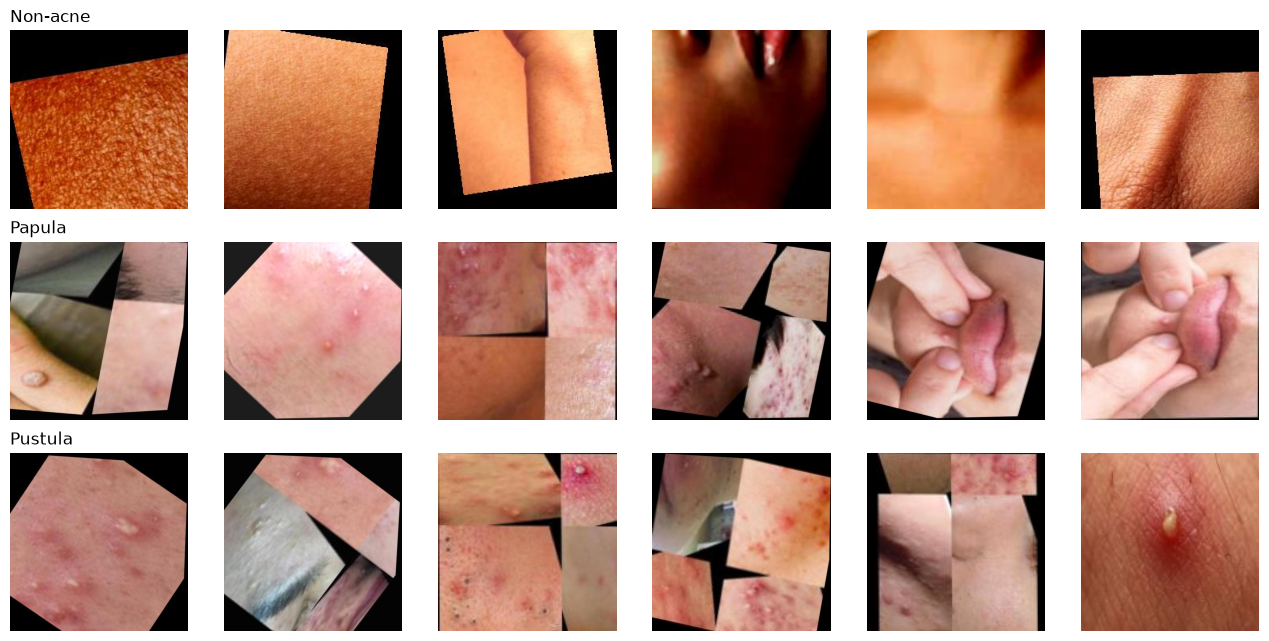

In [6]:
# Contoh citra setiap kelas
fig, axes = plt.subplots(3, 6, figsize=(13, 6.5))
for label in LABEL:
    contoh = df[df["label"] == label].sample(6, random_state=1)["path"]
    for kolom, path in enumerate(contoh):
        axes[label, kolom].imshow(Image.open(ROOT / path))
        axes[label, kolom].axis("off")
    axes[label, 0].set_title(LABEL[label], loc="left")
plt.tight_layout()
plt.show()

## 3. Preprocessing

1. **Konversi grayscale** — RGB → keabuan (0,299R + 0,587G + 0,114B).
2. **Interpolasi citra (resize)** ke 256×300 piksel dengan 3 metode: *bicubic*, *bilinear*, *Lanczos3*
   (di Pillow, `Image.LANCZOS` = kernel Lanczos dengan a = 3).
3. **CLAHE** — *Contrast Limited Adaptive Histogram Equalization*; dipakai sebagai **transformasi uji**
   untuk mengukur kestabilan fitur (bagian 8).

In [7]:
METODE_INTERPOLASI = {
    "bicubic": Image.BICUBIC,
    "bilinear": Image.BILINEAR,
    "lanczos3": Image.LANCZOS,
}


def preprocessing(path, interpolasi="lanczos3"):
    citra = Image.open(path).convert("RGB")
    gray = citra.convert("L")                                        # 1. grayscale
    gray = gray.resize(UKURAN_CITRA, METODE_INTERPOLASI[interpolasi])  # 2. interpolasi
    return np.array(gray)


def transformasi_clahe(gray):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))       # 3. CLAHE
    return clahe.apply(gray)

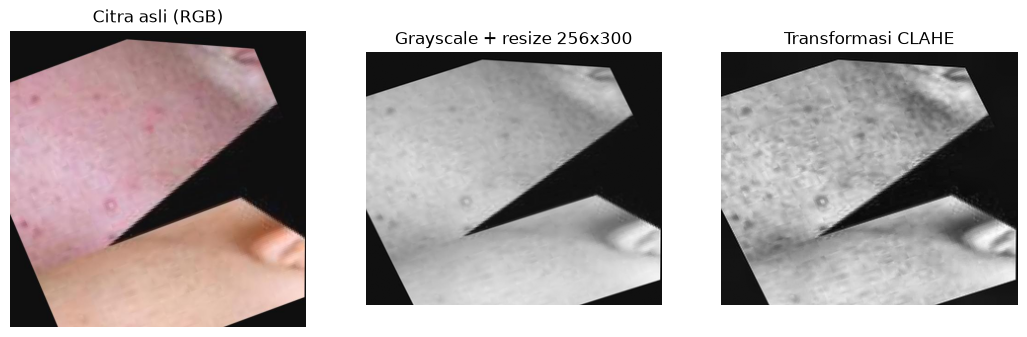

In [8]:
contoh_path = ROOT / df[df["label"] == 2]["path"].iloc[0]
gray = preprocessing(contoh_path, "lanczos3")

tampil = [("Citra asli (RGB)", Image.open(contoh_path)),
          ("Grayscale + resize 256x300", gray),
          ("Transformasi CLAHE", transformasi_clahe(gray))]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (judul, img) in zip(axes, tampil):
    ax.imshow(img, cmap="gray")
    ax.set_title(judul)
    ax.axis("off")
plt.show()

## 4. Ekstraksi fitur SURF (Speeded Up Robust Features)

SURF tidak tersedia di OpenCV versi pip (termasuk algoritma *nonfree*), sehingga diimplementasikan langsung
mengikuti Bay dkk. (2006) dan Oyallon & Rabin (2015) — referensi [17] dan [42] pada jurnal:

1. **Citra integral** → jumlah piksel di dalam kotak dapat dihitung hanya dengan 4 operasi.
2. **Matriks Hessian** didekati dengan *box filter* Dxx, Dyy, Dxy pada beberapa ukuran filter (9, 15, 21, …),
   lalu dihitung `det(H) = Dxx·Dyy − (0,9·Dxy)²`.
3. **Keypoint** = titik maksimum lokal 3×3×3 (posisi & skala) dengan **det(H) ≥ 1000**. Scale `s = 1,2 · L / 9`.
4. **Orientasi** dari respons *Haar wavelet* di sekitar keypoint (radius 6s).
5. **Deskriptor**: jendela 20s dibagi 4×4 subregion; tiap subregion → Σdx, Σdy, Σ|dx|, Σ|dy| → **64 fitur**.

In [9]:
def integral_image(gray):
    ii = np.zeros((gray.shape[0] + 1, gray.shape[1] + 1))
    ii[1:, 1:] = gray.astype(float).cumsum(axis=0).cumsum(axis=1)
    return ii


def jumlah_kotak(ii, baris0, kolom0, baris1, kolom1):
    """Jumlah piksel di kotak [baris0:baris1, kolom0:kolom1]. Koordinat boleh berupa array."""
    tinggi, lebar = ii.shape[0] - 1, ii.shape[1] - 1
    baris0, baris1 = np.clip(baris0, 0, tinggi), np.clip(baris1, 0, tinggi)
    kolom0, kolom1 = np.clip(kolom0, 0, lebar), np.clip(kolom1, 0, lebar)
    return ii[baris1, kolom1] - ii[baris0, kolom1] - ii[baris1, kolom0] + ii[baris0, kolom0]

In [10]:
# Box filter ukuran 9x9: (x0, y0, x1, y1, bobot) -> diperbesar untuk ukuran L lainnya
POLA_DXX = [(0, 2, 3, 7, 1), (3, 2, 6, 7, -2), (6, 2, 9, 7, 1)]
POLA_DYY = [(2, 0, 7, 3, 1), (2, 3, 7, 6, -2), (2, 6, 7, 9, 1)]
POLA_DXY = [(1, 1, 4, 4, 1), (5, 1, 8, 4, -1), (1, 5, 4, 8, -1), (5, 5, 8, 8, 1)]

# Ukuran filter tiap oktaf (3 oktaf x 4 level skala)
OKTAF = [[9, 15, 21, 27], [15, 27, 39, 51], [27, 51, 75, 99]]


def respons_box_filter(ii, pola, L):
    """Respons box filter berukuran LxL untuk SEMUA posisi pada citra sekaligus."""
    tinggi, lebar = ii.shape[0] - 1, ii.shape[1] - 1
    n_baris, n_kolom = tinggi - L + 1, lebar - L + 1
    hasil = np.zeros((n_baris, n_kolom))
    for x0, y0, x1, y1, bobot in pola:
        x0, y0, x1, y1 = [int(v * L / 9 + 0.5) for v in (x0, y0, x1, y1)]
        luas = (x1 - x0) * (y1 - y0)
        jumlah = (ii[y1:y1 + n_baris, x1:x1 + n_kolom] - ii[y0:y0 + n_baris, x1:x1 + n_kolom]
                  - ii[y1:y1 + n_baris, x0:x0 + n_kolom] + ii[y0:y0 + n_baris, x0:x0 + n_kolom])
        hasil += bobot * jumlah / luas
    return hasil


def peta_det_hessian(ii, L):
    """Peta det(H) untuk filter ukuran L, disejajarkan dengan ukuran citra."""
    dxx = respons_box_filter(ii, POLA_DXX, L)
    dyy = respons_box_filter(ii, POLA_DYY, L)
    dxy = respons_box_filter(ii, POLA_DXY, L)
    det = dxx * dyy - (0.9 * dxy) ** 2
    peta = np.zeros((ii.shape[0] - 1, ii.shape[1] - 1))
    tengah = L // 2                                   # pusat filter
    peta[tengah:tengah + det.shape[0], tengah:tengah + det.shape[1]] = det
    return peta


def deteksi_keypoint_surf(gray, threshold=THRESHOLD_HESSIAN):
    """Kembalikan daftar keypoint (urut dari det(H) terbesar) dan citra integral."""
    ii = integral_image(gray)
    keypoints = []
    for ukuran_filter in OKTAF:
        tumpukan = np.stack([peta_det_hessian(ii, L) for L in ukuran_filter])
        maksimum_lokal = maximum_filter(tumpukan, size=3)        # non-maximum suppression 3x3x3
        for level in [1, 2]:                                     # level tengah oktaf
            det = tumpukan[level]
            kandidat = (det >= threshold) & (det == maksimum_lokal[level])
            tepi = ukuran_filter[level + 1] // 2 + 1             # abaikan tepi citra
            kandidat[:tepi, :] = kandidat[-tepi:, :] = False
            kandidat[:, :tepi] = kandidat[:, -tepi:] = False
            for y, x in zip(*np.nonzero(kandidat)):
                keypoints.append({"x": int(x), "y": int(y), "det": float(det[y, x]),
                                  "scale": 1.2 * ukuran_filter[level] / 9})
    keypoints.sort(key=lambda kp: kp["det"], reverse=True)
    return keypoints, ii

In [11]:
def haar_wavelet(ii, x, y, ukuran):
    """Respons Haar wavelet arah x (dx) dan y (dy) di titik (x, y)."""
    r = max(1, int(round(ukuran / 2)))
    x, y = np.round(x).astype(int), np.round(y).astype(int)
    kiri = jumlah_kotak(ii, y - r, x - r, y + r, x)
    kanan = jumlah_kotak(ii, y - r, x, y + r, x + r)
    atas = jumlah_kotak(ii, y - r, x - r, y, x + r)
    bawah = jumlah_kotak(ii, y, x - r, y + r, x + r)
    return kanan - kiri, bawah - atas


def orientasi_keypoint(ii, kp):
    s = kp["scale"]
    i, j = np.meshgrid(np.arange(-6, 7), np.arange(-6, 7))
    di_lingkaran = i**2 + j**2 < 36                          # titik dalam radius 6s
    i, j = i[di_lingkaran], j[di_lingkaran]
    dx, dy = haar_wavelet(ii, kp["x"] + i * s, kp["y"] + j * s, 4 * s)
    bobot = np.exp(-(i**2 + j**2) / (2 * 2.5**2))            # bobot Gaussian
    dx, dy = dx * bobot, dy * bobot
    sudut = np.arctan2(dy, dx)

    terbesar, orientasi = -1, 0.0
    for awal in np.radians(np.arange(0, 360, 5)):            # jendela geser selebar pi/3
        selisih = (sudut - awal + np.pi) % (2 * np.pi) - np.pi
        dalam = np.abs(selisih) < np.pi / 6
        total_dx, total_dy = dx[dalam].sum(), dy[dalam].sum()
        if total_dx**2 + total_dy**2 > terbesar:
            terbesar = total_dx**2 + total_dy**2
            orientasi = np.arctan2(total_dy, total_dx)
    return orientasi


def deskriptor_surf(ii, kp):
    """64 fitur SURF: 4x4 subregion x [sum dx, sum dy, sum |dx|, sum |dy|]."""
    s = kp["scale"]
    teta = orientasi_keypoint(ii, kp)
    cos_t, sin_t = np.cos(teta), np.sin(teta)
    fitur = []
    for sub_y in range(4):
        for sub_x in range(4):
            # 5x5 titik sampel dalam subregion (koordinat relatif, satuan s)
            u, v = np.meshgrid(np.arange(5) + sub_x * 5 - 9.5, np.arange(5) + sub_y * 5 - 9.5)
            px = kp["x"] + s * (u * cos_t - v * sin_t)        # diputar sesuai orientasi
            py = kp["y"] + s * (u * sin_t + v * cos_t)
            dx, dy = haar_wavelet(ii, px, py, 2 * s)
            rx = dx * cos_t + dy * sin_t
            ry = -dx * sin_t + dy * cos_t
            bobot = np.exp(-(u**2 + v**2) / (2 * 3.3**2))
            rx, ry = rx * bobot, ry * bobot
            fitur += [rx.sum(), ry.sum(), np.abs(rx).sum(), np.abs(ry).sum()]
    fitur = np.array(fitur)
    return fitur / (np.linalg.norm(fitur) + 1e-12)            # normalisasi panjang = 1

**Penentuan ROI**: keypoint terkuat (det(H) terbesar) menjadi pusat ROI, dengan sisi = 20 × scale
(ukuran jendela deskriptor SURF, minimal 32 piksel). Jika tidak ada keypoint dengan det(H) ≥ 1000,
SURF bernilai nol dan seluruh citra dipakai sebagai ROI.

In [12]:
def tentukan_roi(kp, tinggi, lebar):
    sisi = int(round(max(32, 20 * kp["scale"])))
    sisi = min(sisi, tinggi, lebar)
    x0 = min(max(int(round(kp["x"] - sisi / 2)), 0), lebar - sisi)   # geser agar tetap di dalam citra
    y0 = min(max(int(round(kp["y"] - sisi / 2)), 0), tinggi - sisi)
    return x0, y0, x0 + sisi, y0 + sisi


def ekstraksi_surf(gray, interpolasi):
    tinggi, lebar = gray.shape
    keypoints, ii = deteksi_keypoint_surf(gray)
    if len(keypoints) > 0:
        kp_terkuat = keypoints[0]
        fitur_surf = deskriptor_surf(ii, kp_terkuat)
        roi = tentukan_roi(kp_terkuat, tinggi, lebar)
    else:
        kp_terkuat = None
        fitur_surf = np.zeros(64)
        roi = (0, 0, lebar, tinggi)
    x0, y0, x1, y1 = roi
    roi_img = Image.fromarray(gray[y0:y1, x0:x1])
    roi_img = roi_img.resize((UKURAN_ROI_HOG, UKURAN_ROI_HOG), METODE_INTERPOLASI[interpolasi])
    return {"fitur_surf": fitur_surf, "ada_keypoint": kp_terkuat is not None,
            "keypoints": keypoints, "roi": roi, "roi_img": np.array(roi_img)}

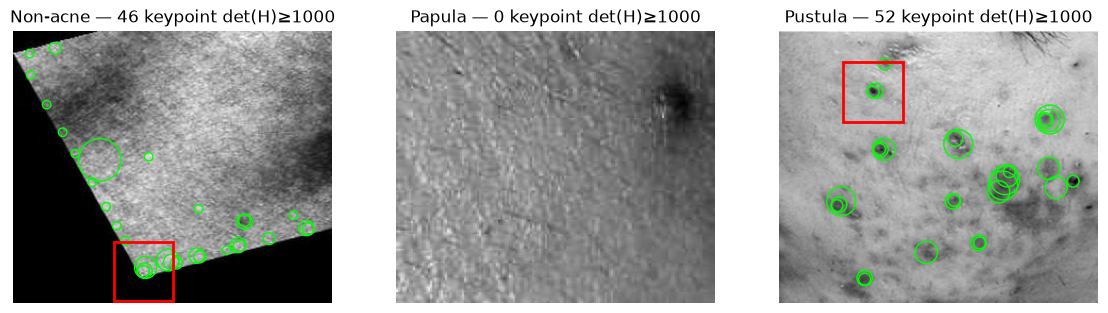

In [13]:
# Visualisasi keypoint SURF & ROI untuk 1 contoh tiap kelas
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))
for label, ax in zip(LABEL, axes):
    path = ROOT / df[df["label"] == label]["path"].iloc[3]
    gray = preprocessing(path, "lanczos3")
    hasil = ekstraksi_surf(gray, "lanczos3")
    ax.imshow(gray, cmap="gray")
    for kp in hasil["keypoints"][:30]:
        ax.add_patch(plt.Circle((kp["x"], kp["y"]), 2 * kp["scale"], color="lime", fill=False))
    if hasil["ada_keypoint"]:
        x0, y0, x1, y1 = hasil["roi"]
        ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, color="red", fill=False, lw=2))
    ax.set_title(f"{LABEL[label]} — {len(hasil['keypoints'])} keypoint det(H)≥1000")
    ax.axis("off")
plt.show()

## 5. Ekstraksi fitur HOG (Histogram of Oriented Gradients)

ROI dari SURF dinormalisasi ke **64×64**, lalu dihitung gradien (magnitude & orientasi),
dikelompokkan ke **9 bin**, dengan **blok 2×2 sel** yang saling *overlap*. Cellsize divariasikan 4, 8, 16, 32.

| Cellsize | Jumlah fitur HOG | Total fitur (SURF 64 + HOG) |
|---|---|---|
| 4×4 | 8.100 | 8.164 |
| 8×8 | 1.764 | 1.828 |
| 16×16 | 324 | 388 |
| 32×32 | 36 | 100 |

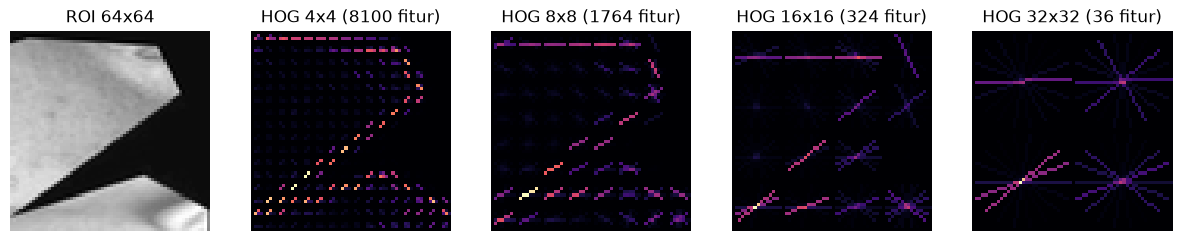

In [14]:
def ekstraksi_hog(roi_img, cellsize, visualisasi=False):
    return hog(roi_img, orientations=9, pixels_per_cell=(cellsize, cellsize),
               cells_per_block=(2, 2), block_norm="L2-Hys", visualize=visualisasi)


hasil = ekstraksi_surf(preprocessing(contoh_path, "lanczos3"), "lanczos3")
fig, axes = plt.subplots(1, 5, figsize=(15, 3.3))
axes[0].imshow(hasil["roi_img"], cmap="gray")
axes[0].set_title("ROI 64x64")
for ax, cellsize in zip(axes[1:], CELLSIZE_LIST):
    fitur, gambar_hog = ekstraksi_hog(hasil["roi_img"], cellsize, visualisasi=True)
    ax.imshow(gambar_hog, cmap="magma")
    ax.set_title(f"HOG {cellsize}x{cellsize} ({len(fitur)} fitur)")
for ax in axes:
    ax.axis("off")
plt.show()

## 6. Ekstraksi fitur seluruh dataset

Untuk setiap metode interpolasi, SURF dihitung **sekali**, lalu HOG dihitung untuk keempat cellsize.
Fitur SURF dan HOG digabung → 3 interpolasi × 4 cellsize = **12 set fitur**.
Hasil disimpan ke `data/processed/fitur.joblib` sehingga tidak perlu dihitung ulang (±5–10 menit).

In [ ]:
FILE_FITUR = PROCESSED_DIR / "fitur.joblib"

if FILE_FITUR.exists():
    fitur_semua, ada_keypoint = joblib.load(FILE_FITUR)
    print("Fitur dimuat dari", FILE_FITUR)
else:
    fitur_semua = {}     # (interpolasi, cellsize) -> matriks fitur
    ada_keypoint = {}    # interpolasi -> True/False per citra
    for interpolasi in INTERPOLASI_LIST:
        mulai = time.time()
        fitur_per_cell = {cellsize: [] for cellsize in CELLSIZE_LIST}
        daftar_kp = []
        for path in df["path"]:
            gray = preprocessing(ROOT / path, interpolasi)
            hasil = ekstraksi_surf(gray, interpolasi)
            daftar_kp.append(hasil["ada_keypoint"])
            for cellsize in CELLSIZE_LIST:
                fitur_hog = ekstraksi_hog(hasil["roi_img"], cellsize)
                fitur_per_cell[cellsize].append(np.concatenate([hasil["fitur_surf"], fitur_hog]))
        for cellsize in CELLSIZE_LIST:
            fitur_semua[(interpolasi, cellsize)] = np.array(fitur_per_cell[cellsize])
        ada_keypoint[interpolasi] = np.array(daftar_kp)
        print(f"{interpolasi:<9} selesai dalam {time.time() - mulai:.0f} detik")
    joblib.dump((fitur_semua, ada_keypoint), FILE_FITUR)

for (interpolasi, cellsize), X in fitur_semua.items():
    print(f"{interpolasi:<9} cellsize {cellsize:>2}x{cellsize:<2} -> {X.shape}")

bicubic   selesai dalam 122 detik


In [ ]:
# Berapa citra yang TIDAK memiliki keypoint det(H) >= 1000 (per kelas)?
tanpa_kp = pd.DataFrame({interp: ~kp for interp, kp in ada_keypoint.items()})
tanpa_kp.groupby(df["label"].map(LABEL)).sum()

## 7. Klasifikasi SVM — 36 kombinasi (Tabel 4 jurnal)

* Fitur gabungan **dinormalisasi** (`StandardScaler`) lalu masuk ke **SVM** (`SVC`) dengan kernel
  *linear*, *polynomial* (`poly`), dan *RBF*.
* Validasi model dengan **5-fold cross-validation** pada data latih.
* Aturan keputusan mengikuti diagram alir pengujian (Gambar 1b): jika citra **tidak punya keypoint
  det(H) ≥ 1000** → *wajah tidak berjerawat* (Non-acne); jika ada → SVM menentukan jenisnya.

In [ ]:
y = df["label"].values
data_latih = (df["split"] == "latih").values
data_uji = (df["split"] == "uji").values


def buat_model(kernel):
    return make_pipeline(StandardScaler(), SVC(kernel=kernel))


def prediksi(model, X, punya_keypoint):
    hasil = model.predict(X)
    hasil[~punya_keypoint] = 0          # tanpa keypoint det(H)>=1000 -> Non-acne
    return hasil


hasil_eksperimen = []
for kernel in KERNEL_LIST:
    for interpolasi in INTERPOLASI_LIST:
        for cellsize in CELLSIZE_LIST:
            X = fitur_semua[(interpolasi, cellsize)]
            kp = ada_keypoint[interpolasi]

            model = buat_model(kernel)
            model.fit(X[data_latih], y[data_latih])
            akurasi_latih = accuracy_score(y[data_latih], prediksi(model, X[data_latih], kp[data_latih]))
            akurasi_uji = accuracy_score(y[data_uji], prediksi(model, X[data_uji], kp[data_uji]))
            skor_cv = cross_val_score(buat_model(kernel), X[data_latih], y[data_latih], cv=5)

            hasil_eksperimen.append({"kernel": kernel, "interpolasi": interpolasi, "cellsize": cellsize,
                                     "latih": akurasi_latih, "uji": akurasi_uji,
                                     "cv": skor_cv.mean()})
            print(f"{kernel:<6} {interpolasi:<9} {cellsize:>2}x{cellsize:<2} "
                  f"latih={akurasi_latih:.2%}  uji={akurasi_uji:.2%}  cv={skor_cv.mean():.2%}")

hasil_df = pd.DataFrame(hasil_eksperimen)
hasil_df.to_csv(REPORT_DIR / "tabel4_akurasi.csv", index=False)

In [ ]:
# Tabel 4 — akurasi (%) per kernel, interpolasi, dan cellsize
tabel4 = hasil_df.pivot_table(index=["kernel", "interpolasi"], columns="cellsize", values=["uji", "latih"])
tabel4 = (tabel4.swaplevel(axis=1).sort_index(axis=1) * 100).round(2)
tabel4

In [ ]:
# Grafik akurasi uji
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, kernel in zip(axes, KERNEL_LIST):
    for interpolasi in INTERPOLASI_LIST:
        baris = hasil_df[(hasil_df["kernel"] == kernel) & (hasil_df["interpolasi"] == interpolasi)]
        ax.plot([f"{c}x{c}" for c in baris["cellsize"]], baris["uji"] * 100, marker="o", label=interpolasi)
    ax.set_title(f"Kernel {kernel}")
    ax.set_xlabel("Cellsize HOG")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Akurasi uji (%)")
axes[0].legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / "akurasi_uji.png", dpi=120)
plt.show()

## 8. Model terbaik & confusion matrix

Model terbaik dipilih dari akurasi uji tertinggi (jika sama, akurasi latih tertinggi).
Sebagai pembanding, jurnal memperoleh hasil terbaik pada **Lanczos3, cellsize 8×8, kernel linear**
(latih 94,75%, uji 93,33%).

In [ ]:
terbaik = hasil_df.sort_values(["uji", "latih"], ascending=False).iloc[0]
kernel, interpolasi, cellsize = terbaik["kernel"], terbaik["interpolasi"], int(terbaik["cellsize"])
print(f"Konfigurasi terbaik: interpolasi={interpolasi}, cellsize={cellsize}x{cellsize}, kernel={kernel}")
print(f"Akurasi latih = {terbaik['latih']:.2%} | Akurasi uji = {terbaik['uji']:.2%}")

X = fitur_semua[(interpolasi, cellsize)]
kp = ada_keypoint[interpolasi]
model_terbaik = buat_model(kernel).fit(X[data_latih], y[data_latih])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nama, bagian) in zip(axes, [("latih", data_latih), ("uji", data_uji)]):
    y_pred = prediksi(model_terbaik, X[bagian], kp[bagian])
    cm = confusion_matrix(y[bagian], y_pred, labels=[0, 1, 2])
    ConfusionMatrixDisplay(cm, display_labels=list(LABEL.values())).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"Data {nama} — akurasi {accuracy_score(y[bagian], y_pred):.2%}")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "confusion_matrix.png", dpi=120)
plt.show()

y_pred_uji = prediksi(model_terbaik, X[data_uji], kp[data_uji])
print(classification_report(y[data_uji], y_pred_uji, target_names=list(LABEL.values()), digits=4))

In [ ]:
# Simpan model terbaik
joblib.dump({"model": model_terbaik, "kernel": kernel, "interpolasi": interpolasi, "cellsize": cellsize},
            MODEL_DIR / "model_terbaik.joblib")
print("Model disimpan ke", MODEL_DIR / "model_terbaik.joblib")

## 9. Analisis similarity fitur (Tabel 3 jurnal)

Fitur dari **citra asli** dibandingkan dengan fitur dari **citra hasil transformasi CLAHE**.
Similarity dihitung dengan **koefisien korelasi Pearson** (seperti `corr2` di MATLAB; referensi [46] jurnal).
Nilai mendekati 1 berarti fitur stabil terhadap perubahan kontras.
Similarity SURF hanya dihitung bila citra asli dan citra CLAHE sama-sama memiliki keypoint.

In [ ]:
def similarity(a, b):
    return np.corrcoef(a, b)[0, 1]


sim_surf, sim_hog = [], []
for path in df["path"]:
    gray = preprocessing(ROOT / path, interpolasi)
    asli = ekstraksi_surf(gray, interpolasi)
    clahe = ekstraksi_surf(transformasi_clahe(gray), interpolasi)
    sim_hog.append(similarity(ekstraksi_hog(asli["roi_img"], cellsize),
                              ekstraksi_hog(clahe["roi_img"], cellsize)))
    if asli["ada_keypoint"] and clahe["ada_keypoint"]:
        sim_surf.append(similarity(asli["fitur_surf"], clahe["fitur_surf"]))

tabel3 = pd.DataFrame({
    "Metode Fitur": ["SURF", "HOG"],
    "Nilai Similarity": [np.nanmean(sim_surf), np.nanmean(sim_hog)],
    "Jumlah citra": [len(sim_surf), len(sim_hog)],
    "Nilai jurnal": [0.8858, 0.9057],
}).round(4)
tabel3.to_csv(REPORT_DIR / "tabel3_similarity.csv", index=False)
tabel3

## 10. Uji coba deteksi pada satu citra

Mengikuti diagram alir pengujian: preprocessing → ekstraksi fitur → cek det(H) → klasifikasi jenis jerawat.
Ganti `path_uji` dengan citra lain untuk mencoba.

In [ ]:
def deteksi_jerawat(path, simpan_model=MODEL_DIR / "model_terbaik.joblib"):
    paket = joblib.load(simpan_model)
    gray = preprocessing(path, paket["interpolasi"])
    hasil = ekstraksi_surf(gray, paket["interpolasi"])
    fitur = np.concatenate([hasil["fitur_surf"], ekstraksi_hog(hasil["roi_img"], paket["cellsize"])])

    if not hasil["ada_keypoint"]:
        keputusan = "Wajah tidak berjerawat (tidak ada keypoint det(H) >= 1000)"
    else:
        kelas = paket["model"].predict([fitur])[0]
        keputusan = "Wajah tidak berjerawat" if kelas == 0 else f"Wajah berjerawat — jenis: {LABEL[kelas]}"

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    axes[0].imshow(Image.open(path))
    axes[0].set_title("Citra input")
    axes[1].imshow(gray, cmap="gray")
    for kp in hasil["keypoints"][:30]:
        axes[1].add_patch(plt.Circle((kp["x"], kp["y"]), 2 * kp["scale"], color="lime", fill=False))
    x0, y0, x1, y1 = hasil["roi"]
    axes[1].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, color="red", fill=False, lw=2))
    axes[1].set_title("Keypoint SURF & ROI")
    axes[2].imshow(ekstraksi_hog(hasil["roi_img"], paket["cellsize"], visualisasi=True)[1], cmap="magma")
    axes[2].set_title("Fitur HOG pada ROI")
    for ax in axes:
        ax.axis("off")
    fig.suptitle(keputusan, fontsize=13)
    plt.show()


path_uji = ROOT / df[(df["split"] == "uji") & (df["label"] == 1)]["path"].iloc[0]
deteksi_jerawat(path_uji)